# Skill selection

**Recipe 28** · Level 3 (Intermediate) · Decision type: `Score`

Score retrieved skill descriptions for relevance to a task so Python can select a suitable skill or request clarification.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

An agent is choosing which of several skills should carry out a task. Python keeps a small, fixed catalog of skills and, for each task, retrieves a short list of candidates by a simple lexical overlap with their own descriptions. Jev then scores exactly one thing, once per candidate: how well that one skill's own description shows it can carry out the task, on a four-level rubric. Python never asks Jev to compare skills against each other; it ranks the candidates itself from their scores and decides, with two separate checks, whether to act automatically: the top skill's own score has to clear a fixed business cutoff, and it has to clearly beat the runner-up by a margin chosen from `validation`. When either check fails -- the best candidate still does not really fit, or two candidates are close enough to be a guess -- the task goes to a person to clarify instead of picking one. By the end you will have seen one relevance `Score` up close for three different tasks (a clear winner, two skills that are genuinely both plausible, and a task no retrieved skill really fits), the rule that composes several such scores into one task-level decision, and an evaluation at both levels: how good each individual relevance score is against its own [gold label](../../docs/glossary.md#gold-label), and how often the composed decision names the right skill versus asks for help.

## Setup and run mode

The notebook runs from its own folder and needs only the standard library and `jev_cookbook`. `get_backend(fixtures=...)` replays stored answers offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls and changes nothing else. The header states which mode ran. Two labels may follow a number below. `(a pipeline check, not a Jev result)` marks a synthetic or scripted run; a recorded or live run does not print it, and its header says which mode ran. `(a selection step, not a reported result)` marks a number from `validation`, the split settings are chosen on; it is never a result to report. A line with neither label, such as an individual answer or a per-example line, still comes from the mode the header names.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    evaluate_outcomes,
    exact_agreement,
    mean_absolute_error,
    score_level,
    select_confidence_threshold,
    selective_curve,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.style import apply_style, plot_risk_coverage, run_header, show_answer

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())
# N for the header is the number of (task, skill) requests the per-question metrics
# below cover: validation and test. The three demo tasks are shown up close but never
# scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
# CONTRIBUTING.md section 2: "a number from the validation split is a selection step,
# not a result." This label does not depend on the run mode, unlike `check` above.
selection = " (a selection step, not a reported result)"

# Every one of the 150 (task, skill) requests in fixtures/ needs at most one request:
# this cache makes sure a request shown individually up close and later reused in an
# evaluation loop is decided once, so the whole notebook makes exactly 150 requests in
# live mode, never more (see "Switch to live" in the README for how that count is
# checked).
answered = {}


def decide(example):
    if example.id not in answered:
        answered[example.id] = backend.decide(helpers.build_state(example.fields), questions)[
            "relevance"
        ]
    return answered[example.id]


run_header(28, "Skill selection", backend=backend, n_examples=len(scored))

Recipe 28: Skill selection
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 141 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees for one (task, skill) pair, and Python builds it. Each example in `fixtures/inputs.jsonl` carries `fields`: a task id, the task's own text, a skill id, and that one skill's own catalog description. `build_state` passes on the task text and the skill's description only -- never the other candidate skills, and never either identifier, so a result always traces back to its task and skill without either one ever passing through the model.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
example = demo["d01-expense_report"]
print("Python has:")
print(json.dumps(example.fields, indent=2))
state = helpers.build_state(example.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "task_id": "d01",
  "task": "Submit my taxi and hotel receipts from last week's client visit for reimbursement.",
  "skill_id": "expense_report",
  "skill": "Files an expense report: submits a receipt for reimbursement and reports the status of a submitted claim."
}
Jev sees:
{
  "task": "Submit my taxi and hotel receipts from last week's client visit for reimbursement.",
  "skill": "Files an expense report: submits a receipt for reimbursement and reports the status of a submitted claim."
}


## The questions

There is one question, `relevance`, and it asks one thing: how well does this one skill's own description show it can carry out this task? A `Score` fits because suitability is a matter of degree, not a single named option, and it lets the evaluation below ask both how good one judgment is against its own gold label and how the composed decision does across several of them. Python builds the four-level rubric from `helpers.SUITABILITY_LEVELS`, lowest level first, and every level is written to stand on its own (TypeSafe's guidance: a `Score` level is judged independently, never "worse than the level above"). The same question is asked once per retrieved candidate skill, never once per task with several skills compared against each other: Jev only ever sees one skill's description at a time, so the comparison between candidates is entirely Python's.

In [3]:
questions = helpers.build_questions()
relevance = questions["relevance"]
print(relevance.instructions)
for level, description in enumerate(relevance.criteria):
    print(f"  {level}  {description}")

How well does this skill's own description show that it can carry out this task? Judge only what this skill's description itself states, not what any other skill might do.
  0  The skill's description names a different kind of action, or a different kind of information, than what the task asks for. Nothing the description states would let this skill carry out the task.
  1  The skill's description names the same general area of work as the task, but it does not state that it performs the specific action, on the specific kind of thing, that the task asks for.
  2  The skill's description states that it performs the specific action the task asks for. The description may also cover other actions the task does not need, or may not name every secondary detail the task mentions.
  3  The skill's description states that it performs the specific action the task asks for, and also names, by itself, the particular detail (the kind of item, the system, or the scope) that the task asks about.


## One answer up close

Before any aggregate, look at the typed answers for three tasks that show the three shapes this recipe's rule can land on. A `Score` answer holds the most probable level (its distribution's peak), a probability for every level, an expected `score` that can fall between two levels, and a `confidence` summarizing how peaked the distribution is -- the probability-weighted distance from the most likely level, divided by the same quantity for an even spread, from [TypeSafe's confidence page](https://docs.typesafe.ai/confidence) (S03). Each task below retrieved three candidate skills; the three cells show every candidate's answer for that task, in the order Python retrieved them.

In [4]:
demo_by_task = helpers.group_by_task_id([e for e in examples if e.split == "demo"])

select_examples = demo_by_task["d01"]
print(select_examples[0].fields["task"])
for example in select_examples:
    skill_id = example.fields["skill_id"]
    print(f"\n{skill_id}: {helpers.SKILL_CATALOG[skill_id]}")
    show_answer(decide(example))

Submit my taxi and hotel receipts from last week's client visit for reimbursement.

travel_booking: Books travel for a trip: reserves a flight, a hotel room, or a rental car and confirms the itinerary.
Score: 0.44 (confidence 0.56)
  0 The skill's description names a different kind of action, or a different kind of information,
    than what the task asks for. Nothing the description states would let this skill carry out the
    task.  0.72  ##############
  1 The skill's description names the same general area of work as the task, but it does not state
    that it performs the specific action, on the specific kind of thing, that the task asks for.  0.16  ###
  2 The skill's description states that it performs the specific action the task asks for. The
    description may also cover other actions the task does not need, or may not name every secondary
    detail the task mentions.  0.08  ##
  3 The skill's description states that it performs the specific action the task asks for, and a

In [5]:
ambiguous_examples = demo_by_task["d02"]
print(ambiguous_examples[0].fields["task"])
for example in ambiguous_examples:
    skill_id = example.fields["skill_id"]
    print(f"\n{skill_id}: {helpers.SKILL_CATALOG[skill_id]}")
    show_answer(decide(example))

Handle the calendar schedule and travel logistics for next week's trip to the Seattle offsite.

travel_booking: Books travel for a trip: reserves a flight, a hotel room, or a rental car and confirms the itinerary.
Score: 2.38 (confidence 0.38)
  0 The skill's description names a different kind of action, or a different kind of information,
    than what the task asks for. Nothing the description states would let this skill carry out the
    task.  0.04  #
  1 The skill's description names the same general area of work as the task, but it does not state
    that it performs the specific action, on the specific kind of thing, that the task asks for.  0.09  ##
  2 The skill's description states that it performs the specific action the task asks for. The
    description may also cover other actions the task does not need, or may not name every secondary
    detail the task mentions.  0.32  ######
  3 The skill's description states that it performs the specific action the task asks for, and

In [6]:
cutoff_examples = demo_by_task["d03"]
print(cutoff_examples[0].fields["task"])
for example in cutoff_examples:
    skill_id = example.fields["skill_id"]
    print(f"\n{skill_id}: {helpers.SKILL_CATALOG[skill_id]}")
    show_answer(decide(example))

Set up a recurring reminder to track my conference travel expenses.

travel_booking: Books travel for a trip: reserves a flight, a hotel room, or a rental car and confirms the itinerary.
Score: 1.17 (confidence 0.65)
  0 The skill's description names a different kind of action, or a different kind of information,
    than what the task asks for. Nothing the description states would let this skill carry out the
    task.  0.09  ##
  1 The skill's description names the same general area of work as the task, but it does not state
    that it performs the specific action, on the specific kind of thing, that the task asks for.  0.71  ##############
  2 The skill's description states that it performs the specific action the task asks for. The
    description may also cover other actions the task does not need, or may not name every secondary
    detail the task mentions.  0.14  ###
  3 The skill's description states that it performs the specific action the task asks for, and also
    names, 

## Python's part

Jev supplies one relevance score per candidate skill; the rule that turns several of those into one task-level decision is code, in `helpers.select_skill`. It ranks the task's candidates by their expected `score` (ties broken by retrieval order, never an incidental later sort), then checks two things, either of which can send the task to [review](../../docs/glossary.md#review) on its own:

- **The business cutoff** (`helpers.BUSINESS_CUTOFF`, fixed, never chosen from data): the top skill's own most probable level must be `suitable` or better. A skill whose description does not even state that it can do the task is never selected, however far ahead of the runner-up it scored.
- **The margin**: the gap between the top skill's expected score and the runner-up's, normalized to 0-1, has to clear a margin threshold chosen on `validation` and frozen below. This is the check for the hard case the use case names: two skills whose descriptions both plausibly fit the task, scored close together. Picking either one without asking is a guess Python should not make automatically.

A task that fails either check is held for a person to clarify which skill is meant -- a clarification is a [review](../../docs/glossary.md#review) outcome, not an action: nothing is sent, assigned, or run, and the task simply waits for a person to say which skill to use. The margin threshold is the one setting chosen from data here: `helpers.select_margin_threshold` picks the highest-accuracy cut-off that still answers at least `helpers.MARGIN_MIN_COVERAGE` of the pool (only the `validation` tasks whose top skill already clears the business cutoff -- a task the cutoff alone would reject can never set the bar for the margin, the same reasoning the template uses for its own [confidence gate](../../docs/glossary.md#confidence-gate)), rather than demanding perfect accuracy on `validation` outright (`target_accuracy=1.0`), which on this pool is not merely a weaker choice -- it is infeasible: the pool's own joint-maximum margin is held by both a correct example and a wrong one, so no non-empty answered set is ever error-free, and asking for one raises `ValueError` rather than handing back a flattering number. Choosing that threshold uses a stricter notion of "correct" than the one this recipe reports elsewhere, `helpers.is_safe_auto_answer`: a task where two skills are genuinely tied counts as *unsafe* to auto-answer for this purpose, whichever one a run happens to rank first -- scoring a lucky guess on a tied task as a success would give the threshold search no reason to ever raise the bar above a razor-thin margin.

This rule has no third, separate check on each top answer's own `Score` confidence -- a confidence gate, the shape several other recipes in this cookbook use. Why not, measured rather than argued, comes after the evaluation below: the measurement needs both splits' selections, so it cannot be shown until `validation` and `test` have both run.

In [7]:
val_examples = select_split(examples, "validation")
val_groups = helpers.group_by_task_id(val_examples)
val_judgments_by_task = {
    task_id: [helpers.judgment_from_answer(e.fields["skill_id"], decide(e)) for e in exs]
    for task_id, exs in val_groups.items()
}
val_gold_best_by_task = {
    task_id: helpers.gold_best_skills({e.fields["skill_id"]: labels[e.id] for e in exs})
    for task_id, exs in val_groups.items()
}
pool_safe, pool_margin = helpers.pool_for_margin_selection(
    val_judgments_by_task, val_gold_best_by_task
)
print(
    f"validation tasks whose top skill clears the business cutoff: "
    f"{len(pool_safe)} of {len(val_groups)}{selection}{check}"
)
margin_threshold = helpers.select_margin_threshold(pool_safe, pool_margin)
print(f"chosen margin threshold, frozen from here on: {margin_threshold:.4f}{selection}{check}")

for task_id in ("d01", "d02", "d03"):
    task_examples = demo_by_task[task_id]
    judgments = [
        helpers.judgment_from_answer(e.fields["skill_id"], decide(e)) for e in task_examples
    ]
    result = helpers.select_skill(task_id, judgments, margin_threshold)
    print(
        f"{task_id}: top {result.skill_id} (level {result.level}, margin "
        f"{result.margin:.4f}) -> {result.outcome} ({result.reason})"
    )

validation tasks whose top skill clears the business cutoff: 22 of 24 (a selection step, not a reported result) (a pipeline check, not a Jev result)
chosen margin threshold, frozen from here on: 0.4033 (a selection step, not a reported result) (a pipeline check, not a Jev result)
d01: top expense_report (level 3, margin 0.7800) -> select (clearly the best-fitting skill)
d02: top travel_booking (level 3, margin 0.0400) -> review (the margin between the top two skills is below the threshold)
d03: top expense_report (level 1, margin 0.0033) -> review (the top skill's modal level is below the business cutoff)


## Evaluation

The margin threshold was chosen and frozen above, on `validation`. This section reports two different things, at two different levels, and keeps them separate: **per question**, how well each individual relevance score agrees with its own gold label -- here, the suitability level a person would have given that one (task, skill) pair, from `fixtures/labels.jsonl`, never shown to Jev; and **per task**, how often `helpers.select_skill`'s composed decision, built from every one of a task's candidate scores, names a correct skill versus sends the task to review. The composed decision is never reimplemented here: every number below comes from calling `helpers.select_skill` and `helpers.outcome_accounting` on the actual answers, the same functions `tests/test_helpers.py` tests directly -- including two tests that delete one check at a time from the committed fixtures and confirm the reported [coverage](../../docs/glossary.md#coverage) and accuracy actually change, not just a reason string. `test` is used once, to report; `validation` numbers are a selection step, labelled as such even where they are not literally what chose the threshold.

In [8]:
val_gold = [labels[e.id] for e in val_examples]
val_answers = [decide(e) for e in val_examples]
print(f"validation, {len(val_examples)} (task, skill) requests{selection}{check}")
print(f"  exact-level agreement: {exact_agreement(val_gold, val_answers):.4f}{selection}{check}")
print(
    f"  mean absolute error: {mean_absolute_error(val_gold, val_answers):.4f} levels"
    f"{selection}{check}"
)

test_examples = select_split(examples, "test")
test_gold = [labels[e.id] for e in test_examples]
test_answers = [decide(e) for e in test_examples]
print(f"\ntest, {len(test_examples)} (task, skill) requests{check}")
print(f"  exact-level agreement: {exact_agreement(test_gold, test_answers):.4f}{check}")
print(f"  mean absolute error: {mean_absolute_error(test_gold, test_answers):.4f} levels{check}")

validation, 72 (task, skill) requests (a selection step, not a reported result) (a pipeline check, not a Jev result)
  exact-level agreement: 0.9444 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  mean absolute error: 0.5171 levels (a selection step, not a reported result) (a pipeline check, not a Jev result)

test, 69 (task, skill) requests (a pipeline check, not a Jev result)
  exact-level agreement: 0.9710 (a pipeline check, not a Jev result)
  mean absolute error: 0.4933 levels (a pipeline check, not a Jev result)


In [9]:
print("test (task, skill) requests the per-question score got wrong:")
for example, answer, gold in zip(test_examples, test_answers, test_gold, strict=True):
    level = score_level(answer)
    if level != gold:
        print(
            f"  {example.id}: gold level {gold}, modal level {level} "
            f"(confidence {answer.confidence:.2f})"
        )

test (task, skill) requests the per-question score got wrong:
  t05-doc_search: gold level 3, modal level 0 (confidence 0.92)
  t05-expense_report: gold level 1, modal level 3 (confidence 0.78)


In [10]:
def task_selections(split_examples, threshold):
    groups = helpers.group_by_task_id(split_examples)
    selections = []
    gold_best_by_task = {}
    for task_id, exs in sorted(groups.items()):
        judgments = [helpers.judgment_from_answer(e.fields["skill_id"], decide(e)) for e in exs]
        gold_best_by_task[task_id] = helpers.gold_best_skills(
            {e.fields["skill_id"]: labels[e.id] for e in exs}
        )
        selections.append(helpers.select_skill(task_id, judgments, threshold))
    return selections, gold_best_by_task


val_selections, val_gold_best = task_selections(val_examples, margin_threshold)
print(f"validation, {len(val_selections)} tasks{selection}{check}")
for s in val_selections:
    if s.outcome != helpers.SELECT:
        print(
            f"  {s.task_id}: {s.skill_id} (level {s.level}, margin {s.margin:.4f}) "
            f"-> {s.outcome} ({s.reason}){selection}{check}"
        )
val_accepted, val_correct = helpers.outcome_accounting(val_selections, val_gold_best)
val_result = evaluate_outcomes(val_accepted, val_correct)
print(f"selected automatically: {val_result.n_answered} of {val_result.n_total}{selection}{check}")
print(f"top-1 accuracy among those selected: {val_result.accuracy:.4f}{selection}{check}")
print(f"clarification rate: {1 - val_result.coverage:.4f}{selection}{check}")
wrong_val = [
    s.task_id
    for s in val_selections
    if s.outcome == helpers.SELECT and s.skill_id not in val_gold_best[s.task_id]
]
print(f"wrongly selected anyway: {wrong_val}{selection}{check}")

validation, 24 tasks (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v03: expense_report (level 1, margin 0.0033) -> review (the top skill's modal level is below the business cutoff) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v04: calendar_scheduling (level 3, margin 0.0233) -> review (the margin between the top two skills is below the threshold) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v05: travel_booking (level 3, margin 0.3300) -> review (the margin between the top two skills is below the threshold) (a selection step, not a reported result) (a pipeline check, not a Jev result)
  v23: calendar_scheduling (level 1, margin 0.4700) -> review (the top skill's modal level is below the business cutoff) (a selection step, not a reported result) (a pipeline check, not a Jev result)
selected automatically: 20 of 24 (a selection step, not a reported result) (a pipeline check, not a Je

In [11]:
test_selections, test_gold_best = task_selections(test_examples, margin_threshold)
print(
    f"\ntest, {len(test_selections)} tasks, margin threshold {margin_threshold:.4f} frozen{check}"
)
for s in test_selections:
    if s.outcome != helpers.SELECT:
        print(
            f"  {s.task_id}: {s.skill_id} (level {s.level}, margin {s.margin:.4f}) "
            f"-> {s.outcome} ({s.reason}){check}"
        )
test_accepted, test_correct = helpers.outcome_accounting(test_selections, test_gold_best)
test_result = evaluate_outcomes(test_accepted, test_correct)
print(f"selected automatically: {test_result.n_answered} of {test_result.n_total}{check}")
print(f"top-1 accuracy among those selected: {test_result.accuracy:.4f}{check}")
print(f"risk among those selected: {test_result.risk:.4f}{check}")
print(f"clarification rate: {1 - test_result.coverage:.4f}{check}")
wrong_test = [
    s.task_id
    for s in test_selections
    if s.outcome == helpers.SELECT and s.skill_id not in test_gold_best[s.task_id]
]
print(f"wrongly selected anyway: {wrong_test}{check}")


test, 23 tasks, margin threshold 0.4033 frozen (a pipeline check, not a Jev result)
  t03: travel_booking (level 1, margin 0.0033) -> review (the top skill's modal level is below the business cutoff) (a pipeline check, not a Jev result)
  t04: travel_booking (level 3, margin 0.0433) -> review (the margin between the top two skills is below the threshold) (a pipeline check, not a Jev result)
  t22: calendar_scheduling (level 1, margin 0.4700) -> review (the top skill's modal level is below the business cutoff) (a pipeline check, not a Jev result)
selected automatically: 20 of 23 (a pipeline check, not a Jev result)
top-1 accuracy among those selected: 0.9500 (a pipeline check, not a Jev result)
risk among those selected: 0.0500 (a pipeline check, not a Jev result)
clarification rate: 0.1304 (a pipeline check, not a Jev result)
wrongly selected anyway: ['t05'] (a pipeline check, not a Jev result)


The cell above is why the margin threshold is not enough on its own to catch every mistake: `t05`'s stored answers confidently score `expense_report` above the skill that actually fits the task (`doc_search`), by a margin wide enough to clear the threshold frozen on `validation`, so `select_skill` names the wrong skill with no review at all. That is exactly the non-zero [risk](../../docs/glossary.md#risk) reported above: the fixtures include this case on purpose (`v22` is its `validation` counterpart, so the threshold is chosen already knowing one wrong example will pass it), and a recipe's evaluation should find it rather than average it away. `v04`/`t04`, by contrast, are the "two skills equally plausible" hard case working as intended: `travel_booking` and `calendar_scheduling` are both genuinely acceptable (the fixtures' own labels record both at gold level 3, in `fixtures/labels.jsonl`), their stored scores land close together, and the margin check correctly sends the task to review instead of guessing between them. `v23`/`t22` show the business cutoff earning its keep the same way: a wide margin on its own would have selected `calendar_scheduling`, but its modal level is only `related`, and the cutoff holds it for review regardless.

### Why this rule has no confidence gate

`python-md` above says this rule has no third, confidence-based check. On this fixture set, with the margin threshold frozen there, one could not do useful work -- not because a `Score` recipe never needs one (it can, and most of this cookbook's recipes do), but because of a property specific to these committed fixtures and this frozen threshold, not to the rubric or to `Score` answers in general; a different recipe, or a differently-drawn set of tasks for this one, could easily need the gate back. The cell below measures it on `validation` first, the way the margin threshold above is chosen, then checks that `test` repeats the same pattern.

In [12]:
def auto_selected_stats(selections, groups, gold_best):
    rows = []
    for s in selections:
        if s.outcome != helpers.SELECT:
            continue
        example = next(e for e in groups[s.task_id] if e.fields["skill_id"] == s.skill_id)
        correct = s.skill_id in gold_best[s.task_id]
        rows.append((s.task_id, decide(example).confidence, correct))
    return rows


test_groups = helpers.group_by_task_id(test_examples)
val_rows = auto_selected_stats(val_selections, val_groups, val_gold_best)
test_rows = auto_selected_stats(test_selections, test_groups, test_gold_best)

val_confidences = [c for _, c, _ in val_rows]
val_wrong = sorted((t, c) for t, c, ok in val_rows if not ok)
val_wrong_top = max(c for _, c in val_wrong)
val_tied = sorted(t for t, c, ok in val_rows if ok and c == val_wrong_top)
print(
    f"validation auto-selected confidence: {min(val_confidences):.2f} to "
    f"{max(val_confidences):.2f}{selection}{check}"
)
val_wrong_text = ", ".join(f"{t} {c:.2f}" for t, c in val_wrong)
print(f"validation wrong selection's confidence: {val_wrong_text}{selection}{check}")
print(
    f"validation correct selections tied with the wrong one's confidence "
    f"({val_wrong_top:.2f}): {val_tied}{selection}{check}"
)

house_gate = select_confidence_threshold(
    [ok for _, _, ok in val_rows], val_confidences, min_coverage=helpers.MARGIN_MIN_COVERAGE
)
newly_reviewed = sum(1 for c in val_confidences if c < house_gate)
print(
    f"a confidence gate chosen by select_confidence_threshold on this pool: "
    f"{house_gate:.2f}{selection}{check}"
)
print(
    f"tasks that gate would newly send to review: {newly_reviewed} of "
    f"{len(val_confidences)}{selection}{check}"
)

test_confidences = [c for _, c, _ in test_rows]
test_wrong = sorted((t, c) for t, c, ok in test_rows if not ok)
test_wrong_top = max(c for _, c in test_wrong)
test_tied = sorted(t for t, c, ok in test_rows if ok and c == test_wrong_top)
print(
    f"\ntest auto-selected confidence: {min(test_confidences):.2f} to "
    f"{max(test_confidences):.2f}{check}"
)
test_wrong_text = ", ".join(f"{t} {c:.2f}" for t, c in test_wrong)
print(f"test wrong selection's confidence: {test_wrong_text}{check}")
print(
    f"test correct selections tied with the wrong one's confidence "
    f"({test_wrong_top:.2f}): {test_tied}{check}"
)

test_newly_reviewed = sum(1 for c in test_confidences if c < house_gate)
print(f"the same gate, chosen above, applied to this pool: {house_gate:.2f}{check}")
print(
    f"tasks that gate would newly send to review: {test_newly_reviewed} of "
    f"{len(test_confidences)}{check}"
)

validation auto-selected confidence: 0.19 to 0.78 (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation wrong selection's confidence: v22 0.78 (a selection step, not a reported result) (a pipeline check, not a Jev result)
validation correct selections tied with the wrong one's confidence (0.78): ['v01'] (a selection step, not a reported result) (a pipeline check, not a Jev result)
a confidence gate chosen by select_confidence_threshold on this pool: 0.19 (a selection step, not a reported result) (a pipeline check, not a Jev result)
tasks that gate would newly send to review: 0 of 20 (a selection step, not a reported result) (a pipeline check, not a Jev result)

test auto-selected confidence: 0.19 to 0.78 (a pipeline check, not a Jev result)
test wrong selection's confidence: t05 0.78 (a pipeline check, not a Jev result)
test correct selections tied with the wrong one's confidence (0.78): ['t01'] (a pipeline check, not a Jev result)
the same gate, cho

`validation`'s one wrong auto-selection sits at the top of that split's own auto-selected confidence range, tied with one correct selection at the same value; `test` repeats the same shape exactly. The tie is not a coincidence either split's fixtures happen to discover -- it is arranged: `build_fixtures.py`'s `TASK_SPECS` gives `v01`, `v22`, `t01` and `t05`'s top skill the same probability vector, `IDEAL_CONFIDENT`. Nor is it the global maximum: some unselected candidates elsewhere in these fixtures score higher still (up to `0.92`), just never as the top, auto-selected answer for their own task.

What that tie rules out is only part of the argument: a gate strictly above the printed confidence would exclude the mistake, but it excludes the correct selection tied there too, and every other correct selection this rule gets right -- any gate at or below it excludes neither. The more decisive fact is printed above: calling `select_confidence_threshold` on `validation`'s own auto-selected pool, the same way `helpers.select_margin_threshold` is chosen, returns the lowest confidence observed there, and a gate set there sends zero tasks to review on either split. A confidence gate chosen the way this cookbook actually chooses gates is not merely unhelpful on this fixture set -- it is inert, which is a stronger reason than the tie by itself. The transferable question for a later recipe is not "are my mistakes high-confidence"; it is "would a gate chosen by `select_confidence_threshold` on my own validation pool change any committed outcome" -- if not, the branch is dead, and the standard this recipe's own `test_deleting_the_business_cutoff_changes_a_reported_outcome_on_the_committed_fixtures` and `test_deleting_the_margin_check_changes_a_reported_outcome_on_the_committed_fixtures` hold the other two branches to is exactly the standard a dead branch fails. `helpers.py`'s own comment above `select_skill` works through this in full, and `tests/test_helpers.py` checks the tie directly, per split (`test_no_confidence_gate_could_have_caught_the_wrong_selections_without_also_losing_correct_ones`), so a future fixture edit that changes it is caught rather than leaving this paragraph stale.

margin sweep over the validation pool, each distinct margin as a gate:
  gate 0.7800: coverage 0.0909, accuracy 0.5000, risk 0.5000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.7600: coverage 0.2273, accuracy 0.8000, risk 0.2000 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.7167: coverage 0.3636, accuracy 0.8750, risk 0.1250 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.6933: coverage 0.5000, accuracy 0.9091, risk 0.0909 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.6667: coverage 0.6364, accuracy 0.9286, risk 0.0714 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.6367: coverage 0.7727, accuracy 0.9412, risk 0.0588 (a selection step, not a reported result) (a pipeline check, not a Jev result)
  gate 0.6133: coverage 0.8182, accuracy 0.9444, risk 0.0556 (a selection step, not a rep

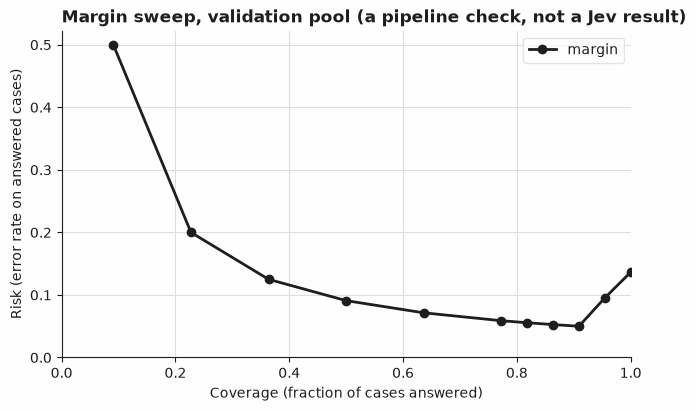

In [13]:
curve = selective_curve(pool_safe, pool_margin)
print("margin sweep over the validation pool, each distinct margin as a gate:")
for t, cov, acc, risk in zip(
    curve.thresholds, curve.coverage, curve.accuracy, curve.risk, strict=True
):
    print(
        f"  gate {t:.4f}: coverage {cov:.4f}, accuracy {acc:.4f}, risk {risk:.4f}{selection}{check}"
    )

plot_risk_coverage(curve, label="margin", title=f"Margin sweep, validation pool{check}")

## What was and was not measured

What this run can say about Jev depends on its mode, which the cell below states from `backend.mode`: a synthetic or scripted run is a pipeline check only, on the fixture sample it ran against; a recorded or live run states the model the API returned and when, for exactly the examples it covers. Nothing here says anything about Jev's quality, speed or cost unless that cell reports a recorded or live run. Two `N`s are stated below, because two different things are reported above: the number of (task, skill) requests the per-question agreement covers, and the number of tasks the composed, task-level decision covers. The three `demo` tasks shown earlier are excluded from both.

In [14]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(
        f"N: {len(val_examples)} validation and {len(test_examples)} test "
        f"(task, skill) requests{check}"
    )
    print(f"N: {len(val_selections)} validation and {len(test_selections)} test tasks{check}")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test (task, skill) requests")
    print(f"N: {len(val_selections)} validation and {len(test_selections)} test tasks")

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 72 validation and 69 test (task, skill) requests (a pipeline check, not a Jev result)
N: 24 validation and 23 test tasks (a pipeline check, not a Jev result)


## Next steps

- Change one sentence in `helpers.SUITABLE` (or any other rubric level) and run `pytest recipes/28-skill-selection` or this notebook: the stored keys no longer match the question, so replay misses instead of guessing. `python build_fixtures.py` writes new keys but rewrites the committed fixtures; `git checkout recipes/28-skill-selection` restores them.
- Raise `helpers.MARGIN_MIN_COVERAGE` from `0.5` to `0.95` and rerun the `python-rule` and evaluation cells: the frozen margin threshold drops from about `0.40` to about `0.33`, loose enough to let `v05`'s wrong, moderate-margin pick through too, joining `v22` -- `validation` already carries one uncaught mistake at the committed threshold (`evaluation-curve` prints it above, `gate 0.4033: ... risk 0.0500`); watch that risk roughly double, to `0.0952` at `gate 0.3300`, printed the same way, rather than appearing there for the first time.
- Add a task to `build_fixtures.py` whose two closest candidates score even closer than `v04`'s or `t04`'s, run `python build_fixtures.py`, and see whether the margin threshold chosen on `validation` moves.
- Neighbouring recipes: [`11-clarification-selection`](../11-clarification-selection/) (`Choice`, this recipe's own `Agent orchestration` category -- the same ask-or-proceed shape, over a fixed catalog of follow-up questions instead of a skill catalog), [`17-passage-reranking`](../17-passage-reranking/) (`Score`, `Search & retrieval` -- the same one-`Score`-per-candidate pattern this recipe retrieves and ranks with), and [`29-tool-outcome-verification`](../29-tool-outcome-verification/) (`Choice`), another `Agent orchestration` recipe that composes more than one judgment into a single decision.